# Heart Disease Prediction
Logistic Regression and Random Forest using the supplied Cleveland CSV.

Assumed labels: **0 = disease absent, 1 = disease present**. Educational project only.

## 1. Import Libraries

In [1]:
import json
from pathlib import Path
import joblib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay, roc_auc_score)

sns.set_theme(style="whitegrid")

## 2. Load Data

In [2]:
df = pd.read_csv("heart_disease_cleveland.csv", na_values=["?"])
print("Shape:", df.shape)
df.head()

Shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [3]:
df.info()
df.describe().round(2)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.00,303.00,303.00,303.00,303.00,303.00,303.00,303.00,303.00,303.00,303.00,299.00,301.00,303.00
mean,54.44,0.68,3.16,131.69,246.69,0.15,0.99,149.61,0.33,1.04,1.60,0.67,4.73,0.46
std,9.04,0.47,0.96,17.60,51.78,0.36,0.99,22.88,0.47,1.16,0.62,0.94,1.94,0.50
min,29.00,0.00,1.00,94.00,126.00,0.00,0.00,71.00,0.00,0.00,1.00,0.00,3.00,0.00
25%,48.00,0.00,3.00,120.00,211.00,0.00,0.00,133.50,0.00,0.00,1.00,0.00,3.00,0.00
50%,56.00,1.00,3.00,130.00,241.00,0.00,1.00,153.00,0.00,0.80,2.00,0.00,3.00,0.00
75%,61.00,1.00,4.00,140.00,275.00,0.00,2.00,166.00,1.00,1.60,2.00,1.00,7.00,1.00
max,77.00,1.00,4.00,200.00,564.00,1.00,2.00,202.00,1.00,6.20,3.00,3.00,7.00,1.00


## 3. Data Cleaning
Check missing values and remove duplicates. Missing inputs will be filled after splitting the data.

In [4]:
print("Missing values:")
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

df = df.drop_duplicates()
df = df.dropna(subset=["target"])
print("Cleaned shape:", df.shape)

Missing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64
Duplicates: 0
Cleaned shape: (303, 14)


No duplicate rows. Missing values: `ca` = 4 and `thal` = 2. Keep unusual measurements because they are not confirmed errors.

## 4. Exploratory Data Analysis (EDA)

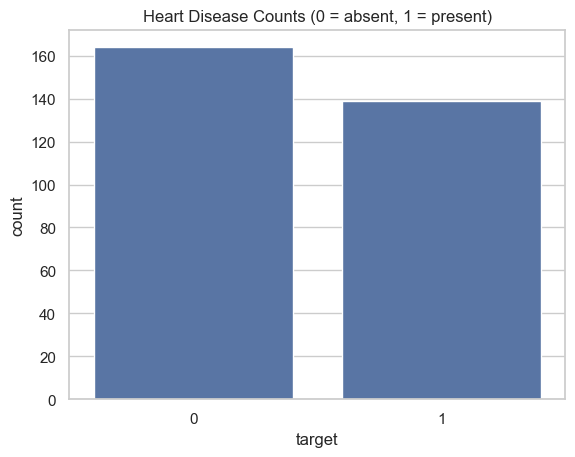

target
0    164
1    139
Name: count, dtype: int64


In [5]:
sns.countplot(data=df, x="target")
plt.title("Heart Disease Counts (0 = absent, 1 = present)")
plt.show()
print(df["target"].value_counts())

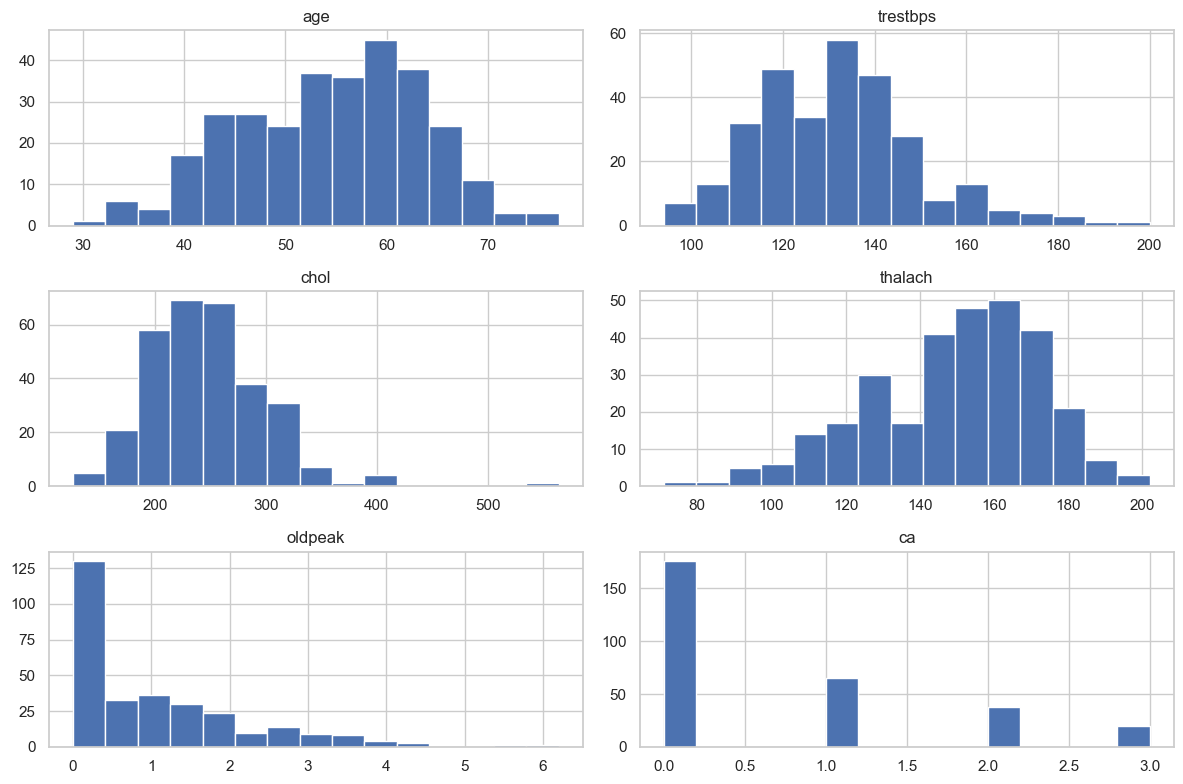

In [6]:
numeric_columns = ["age", "trestbps", "chol", "thalach", "oldpeak", "ca"]
category_columns = ["sex", "cp", "fbs", "restecg", "exang", "slope", "thal"]

df[numeric_columns].hist(figsize=(12, 8), bins=15)
plt.tight_layout()
plt.show()

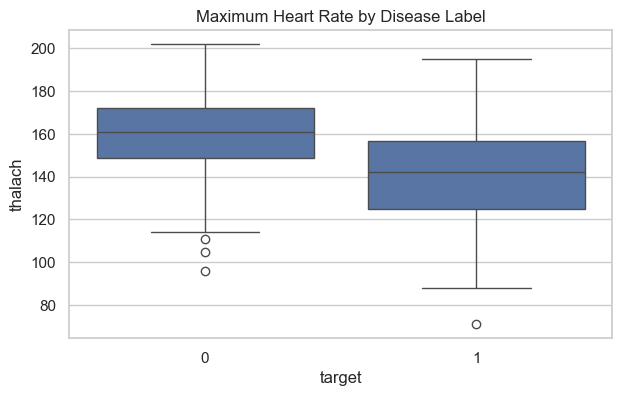

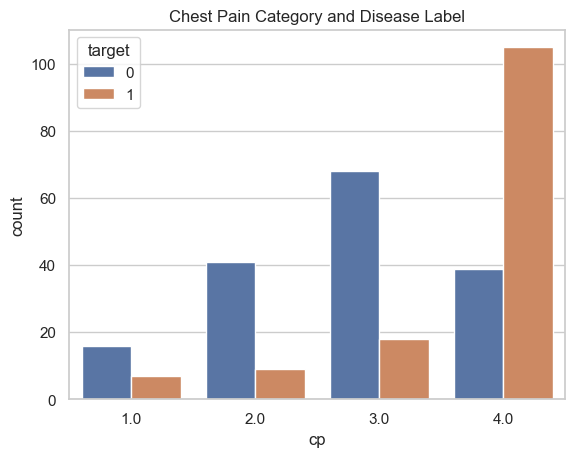

In [7]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="target", y="thalach")
plt.title("Maximum Heart Rate by Disease Label")
plt.show()

sns.countplot(data=df, x="cp", hue="target")
plt.title("Chest Pain Category and Disease Label")
plt.show()

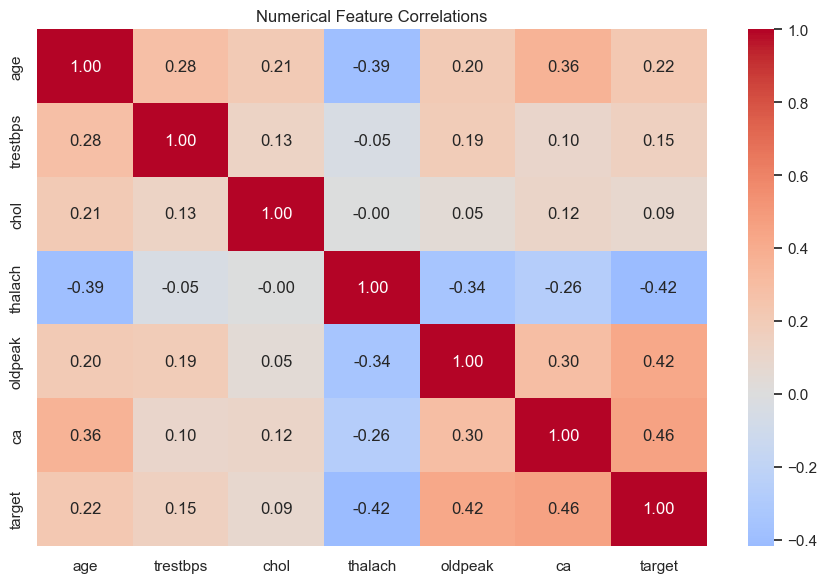

In [8]:
plt.figure(figsize=(9, 6))
sns.heatmap(df[numeric_columns + ["target"]].corr(), annot=True,
            fmt=".2f", cmap="coolwarm", center=0)
plt.title("Numerical Feature Correlations")
plt.tight_layout()
plt.show()

There are 164 class-0 and 139 class-1 records. Chest pain category 4 has more class-1 records. These are dataset patterns, not medical conclusions.

## 5. Data Preprocessing
Use an 80/20 split. Fit imputation, encoding, and scaling only on training data.

In [9]:
X = df.drop(columns="target")
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (242, 13)
Testing: (61, 13)


In [10]:
numeric_steps = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
category_steps = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_steps, numeric_columns),
    ("category", category_steps, category_columns)
], verbose_feature_names_out=False)

## 6. Train Models
Each model gets a separate copy of the preprocessing steps. Random Forest also works with scaled inputs.

In [11]:
logistic_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])
forest_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1))
])
models = {"Logistic Regression": logistic_model, "Random Forest": forest_model}

Choose the app model using training cross-validation ROC-AUC, before checking the test results.

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_rows = []

for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc")
    cv_rows.append({"Model": name, "CV ROC-AUC mean": scores.mean()})
    model.fit(X_train, y_train)

cv_results = pd.DataFrame(cv_rows)
selected_name = cv_results.loc[cv_results["CV ROC-AUC mean"].idxmax(), "Model"]
print("Selected model:", selected_name)
cv_results.round(4)

Selected model: Logistic Regression


,Model,CV ROC-AUC mean
0,Logistic Regression,0.9065
1,Random Forest,0.8844


## 7. Model Evaluation
Class 1 is the disease class. Recall measures how many actual disease cases the model finds.

In [13]:
results = []

for name, model in models.items():
    prediction = model.predict(X_test)
    probability = model.predict_proba(X_test)[:, 1]
    matrix = confusion_matrix(y_test, prediction)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, prediction),
        "Precision (1)": precision_score(y_test, prediction, zero_division=0),
        "Recall (1)": recall_score(y_test, prediction, zero_division=0),
        "F1 (1)": f1_score(y_test, prediction, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probability),
        "False negatives": int(matrix[1, 0])
    })
    print(name)
    print(classification_report(y_test, prediction, target_names=["Absent", "Present"],
                                zero_division=0))

results = pd.DataFrame(results)
results.round(4)

Logistic Regression
              precision    recall  f1-score   support

      Absent       0.93      0.82      0.87        33
     Present       0.81      0.93      0.87        28

    accuracy                           0.87        61
   macro avg       0.87      0.87      0.87        61
weighted avg       0.88      0.87      0.87        61

Random Forest
              precision    recall  f1-score   support

      Absent       0.93      0.85      0.89        33
     Present       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61



,Model,Accuracy,Precision (1),Recall (1),F1 (1),ROC-AUC,False negatives
0,Logistic Regression,0.8689,0.8125,0.9286,0.8667,0.9578,2
1,Random Forest,0.8852,0.8387,0.9286,0.8814,0.9389,2


### Confusion Matrices
Rows = actual labels; columns = predicted labels. Bottom-left = missed disease cases.

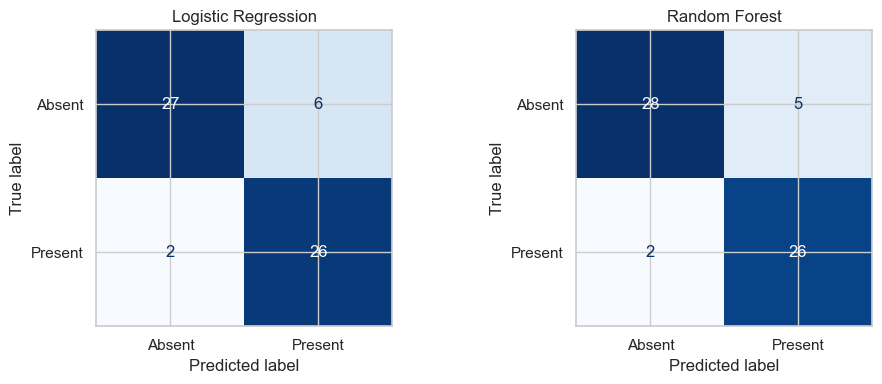

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for (name, model), ax in zip(models.items(), axes):
    ConfusionMatrixDisplay.from_predictions(
        y_test, model.predict(X_test), display_labels=["Absent", "Present"],
        cmap="Blues", colorbar=False, ax=ax
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

### ROC Curves

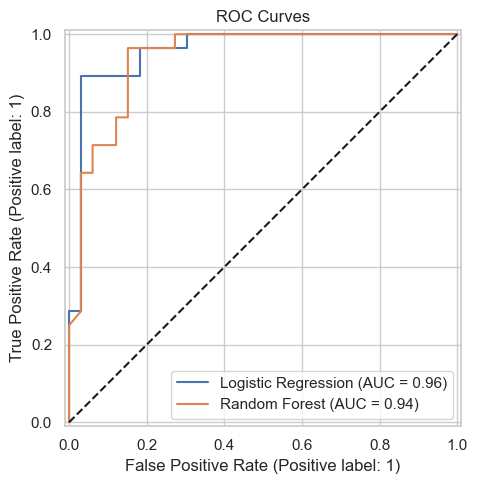

In [15]:
fig, ax = plt.subplots(figsize=(7, 5))
for name, model in models.items():
    RocCurveDisplay.from_predictions(
        y_test, model.predict_proba(X_test)[:, 1], name=name, ax=ax
    )
ax.plot([0, 1], [0, 1], "k--")
plt.title("ROC Curves")
plt.tight_layout()
plt.show()

## 8. Random Forest Feature Importance
Add the importance of encoded categories back to their original feature. Importance shows model influence, not causation.

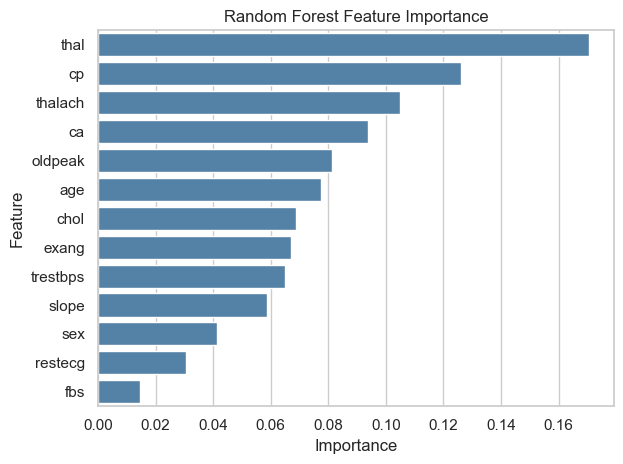

,Feature,Importance
0,thal,0.1707
1,cp,0.1262
2,thalach,0.1049
3,ca,0.0939
4,oldpeak,0.0813
5,age,0.0775
6,chol,0.0689
7,exang,0.0669
8,trestbps,0.0648
9,slope,0.0587


In [16]:
names = forest_model.named_steps["preprocessor"].get_feature_names_out()
importance = pd.Series(forest_model.named_steps["model"].feature_importances_, index=names)

# Example: cp_1.0 and cp_2.0 both belong to cp.
importance.index = importance.index.str.split("_").str[0]
importance = importance.groupby(level=0).sum().sort_values(ascending=False)
feature_importance = importance.rename_axis("Feature").reset_index(name="Importance")

sns.barplot(data=feature_importance, x="Importance", y="Feature", color="steelblue")
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()
feature_importance.round(4)

### Key Medical Factors

In [17]:
print("Top five factors:")
print(feature_importance.head(5).to_string(index=False))

print("Average numerical measurements by disease label:")
df.groupby("target")[["thalach", "ca", "oldpeak"]].mean().round(2)

Top five factors:
Feature  Importance
   thal    0.170708
     cp    0.126217
thalach    0.104850
     ca    0.093857
oldpeak    0.081257
Average numerical measurements by disease label:


,thalach,ca,oldpeak
target,,,
0,158.38,0.27,0.59
1,139.26,1.14,1.57


`thal` = thallium scan, `cp` = chest pain category, `thalach` = maximum heart rate, `ca` = vessel count, and `oldpeak` = ST depression. These are important predictive factors in this Random Forest.

## 9. Save the Model for Streamlit
Save the full pipeline so the app uses the same preprocessing. Keep the selected model trained on the training set.

In [18]:
best_model = models[selected_name]
joblib.dump(best_model, "heart_disease_model.joblib", compress=3)

# The existing Streamlit app reads these results and input ranges.
ranges = {}
for column in numeric_columns:
    ranges[column] = {"min": float(X_train[column].min()),
                      "max": float(X_train[column].max()),
                      "median": float(X_train[column].median())}

metadata = {
    "selected_model": selected_name,
    "selection_rule": "Highest mean 5-fold training CV ROC-AUC",
    "features": X.columns.tolist(), "numeric_ranges": ranges,
    "train_rows": len(X_train), "test_rows": len(X_test),
    "cv_results": cv_results.to_dict(orient="records"),
    "test_results": results.to_dict(orient="records"),
    "random_forest_importance": feature_importance.to_dict(orient="records")
}
Path("model_results.json").write_text(json.dumps(metadata, indent=2))
print("Saved model:", selected_name)

Saved model: Logistic Regression


## 10. Conclusion
Compare accuracy, recall, and ROC-AUC in the results table. The app model is chosen by training cross-validation, not test accuracy. This small historical dataset does not establish clinical reliability.

The Streamlit interface is already in `app.py`. Run it from this folder:

```bash
python -m streamlit run app.py
```

See `README.md` for installation and hosting. [Dataset definitions](https://archive.ics.uci.edu/dataset/45/heart+disease).